In [18]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

def plot_signal_distributions_before_after(raw_df, calibrated_df, target_activity='walk'):
    """
    Computes magnitude from (x, y, z) and plots Kernel Density Estimates (KDE) 
    comparing raw vs calibrated signals across devices.
    """
    # 1. Compute magnitude on raw and calibrated signal frames
    raw_df = raw_df[raw_df['gt'] == target_activity].copy()
    calibrated_df = calibrated_df[calibrated_df['gt'] == target_activity].copy()

    raw_df['acc_mag'] = np.sqrt(raw_df['x']**2 + raw_df['y']**2 + raw_df['z']**2)
    calibrated_df['acc_mag'] = np.sqrt(calibrated_df['x']**2 + calibrated_df['y']**2 + calibrated_df['z']**2)

    # 2. Plotting
    sns.set_theme(style="whitegrid", palette="muted")
    fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=True)

    # Before Calibration
    sns.kdeplot(
        data=raw_df,
        x='acc_mag',
        hue='Model',
        common_norm=False,
        fill=True,
        alpha=0.3,
        linewidth=2,
        ax=axes[0]
    )
    axes[0].set_title(f"BEFORE Calibration: '{target_activity}' (Acceleration Magnitude)", fontsize=13, fontweight='bold')
    axes[0].set_xlabel("Magnitude (m/s²)", fontsize=11)
    axes[0].set_ylabel("Density", fontsize=11)

    # After Calibration
    sns.kdeplot(
        data=calibrated_df,
        x='acc_mag',
        hue='Model',
        common_norm=False,
        fill=True,
        alpha=0.3,
        linewidth=2,
        ax=axes[1]
    )
    axes[1].set_title(f"AFTER Calibration: '{target_activity}' (Acceleration Magnitude)", fontsize=13, fontweight='bold')
    axes[1].set_xlabel("Magnitude (m/s²)", fontsize=11)

    plt.tight_layout()
    plt.show()

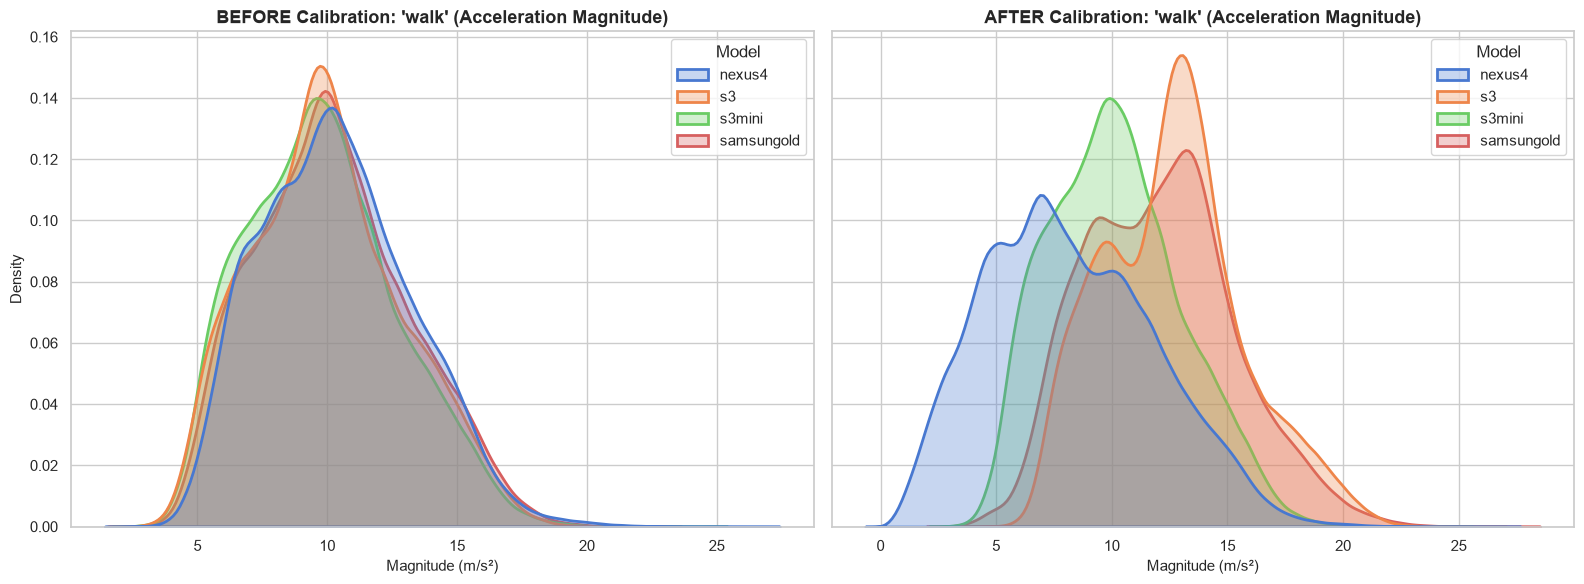

In [19]:
raw_df = pd.read_csv(rf'../ignore_files/data/full/Phones_accelerometer.csv', index_col=0)
cal_df = pd.read_csv(rf'../ignore_files/data/full_calibrated/Calibrated_Phones_accelerometer.csv', index_col=0)

plot_signal_distributions_before_after(raw_df, cal_df)

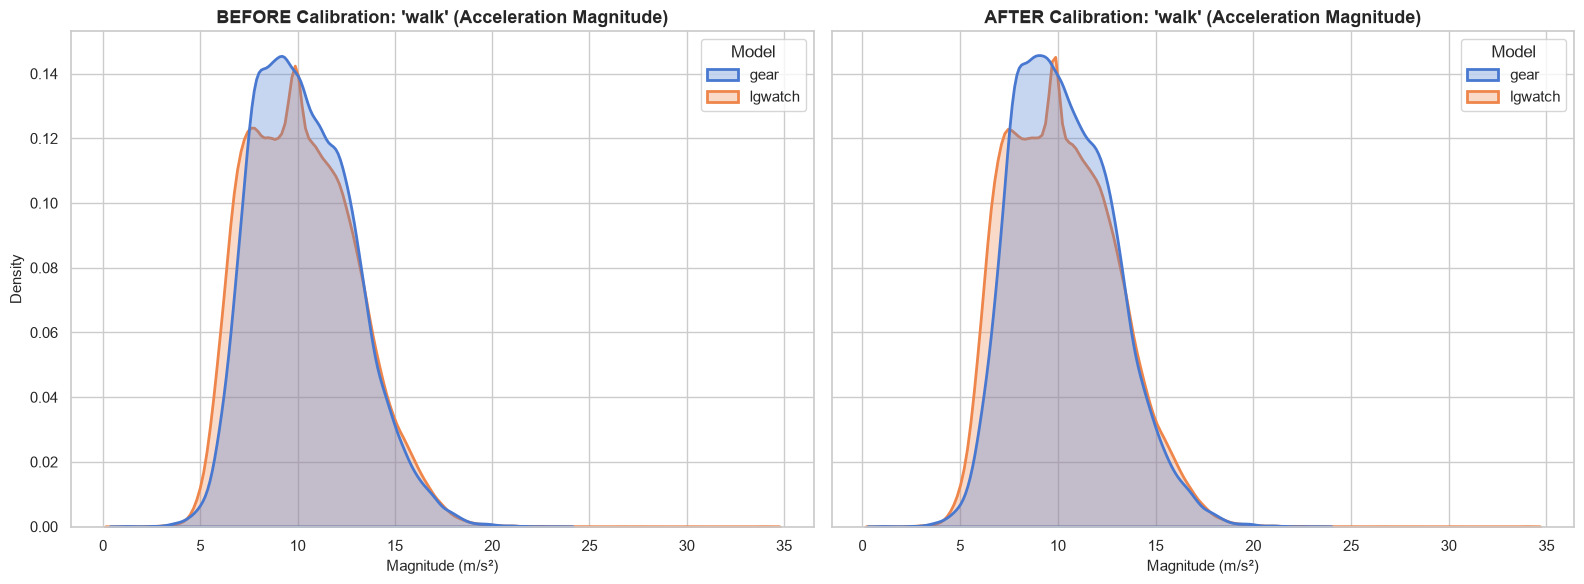

In [20]:
raw_df = pd.read_csv(rf'../ignore_files/data/full/Watch_accelerometer.csv', index_col=0)
cal_df = pd.read_csv(rf'../ignore_files/data/full_calibrated/Calibrated_Watch_accelerometer.csv', index_col=0)

plot_signal_distributions_before_after(raw_df, cal_df)

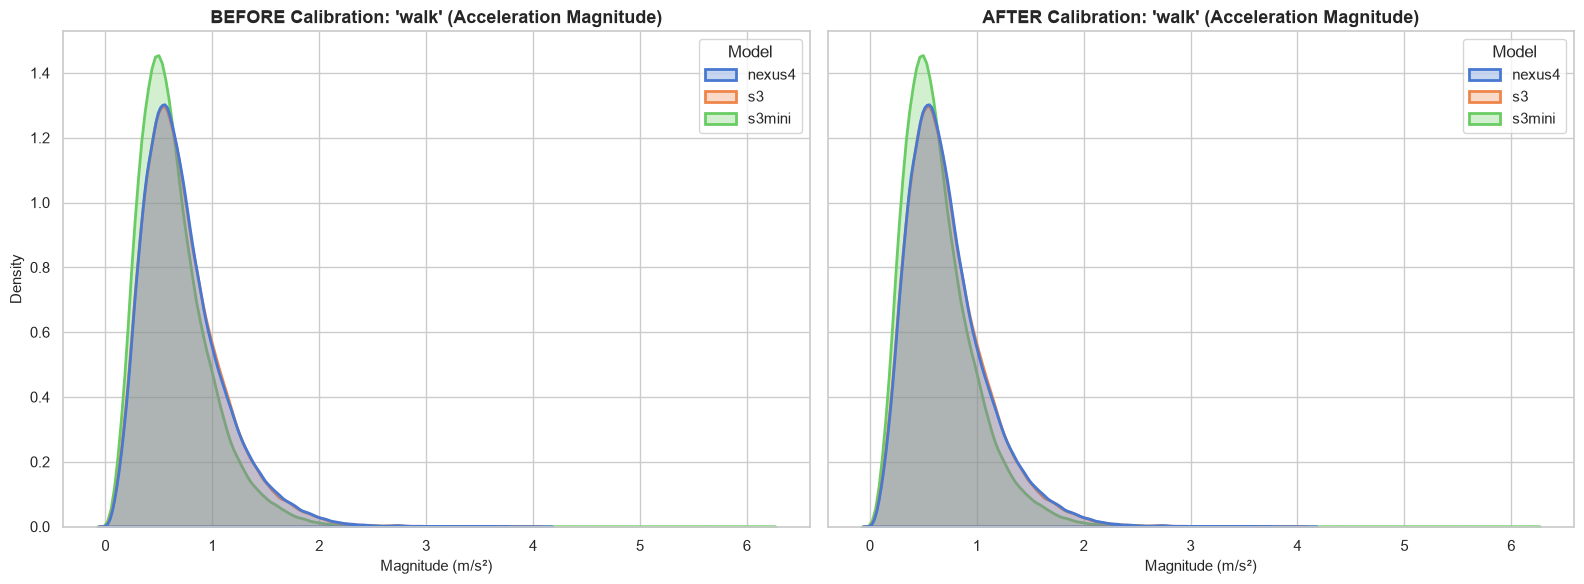

In [21]:
raw_df = pd.read_csv(rf'../ignore_files/data/full/Phones_gyroscope.csv', index_col=0)
cal_df = pd.read_csv(rf'../ignore_files/data/full_calibrated/Calibrated_Phones_gyroscope.csv', index_col=0)

plot_signal_distributions_before_after(raw_df, cal_df)

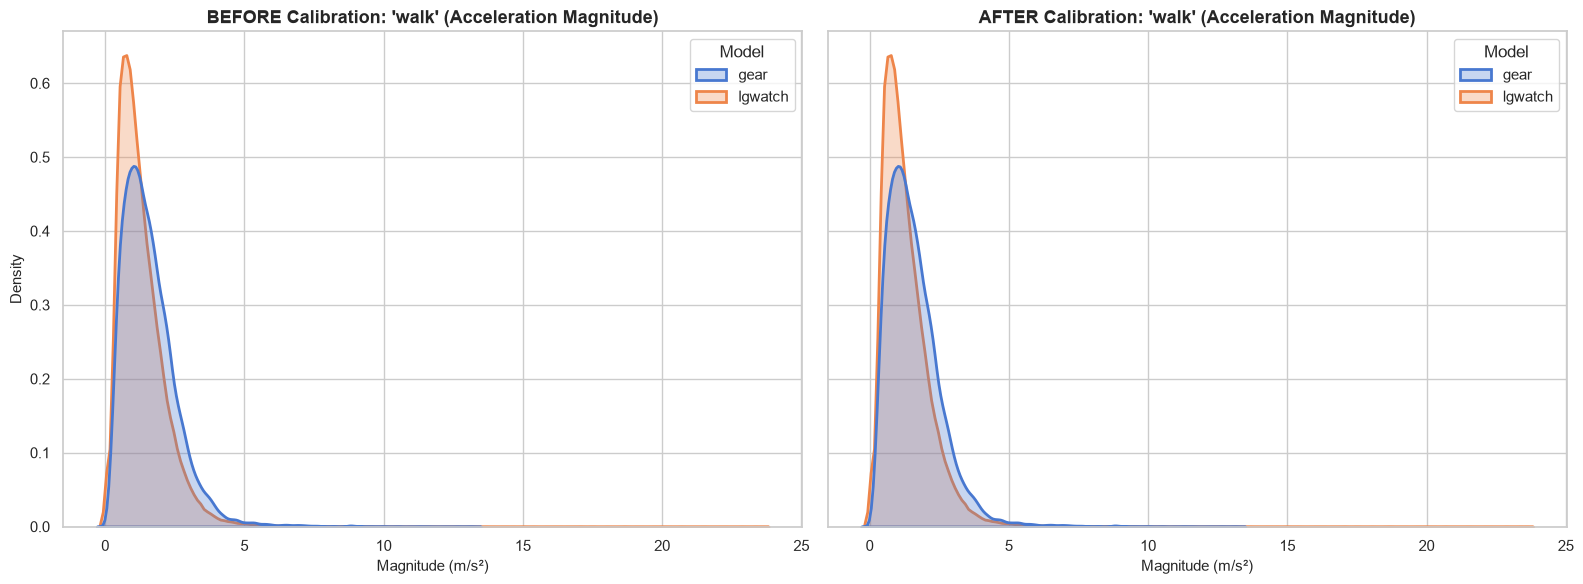

In [22]:
raw_df = pd.read_csv(rf'../ignore_files/data/full/Watch_gyroscope.csv', index_col=0)
cal_df = pd.read_csv(rf'../ignore_files/data/full_calibrated/Calibrated_Watch_gyroscope.csv', index_col=0)

plot_signal_distributions_before_after(raw_df, cal_df)